# Step 3: Road and rules

The three rules a generated path must keep (stay on the road, speed ≤ 15 m/s, acceleration ≤ 6 m/s²), written so a computer can check them, and a check that real driving passes them. Output: `data_processed/road_grid.npz`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

DATA = "../data/"
OUT = "../data_processed/"
DT = 0.2
V_MAX = 15.0    # m/s
A_MAX = 6.0     # m/s^2
CELL = 0.2      # road grid cell size in metres

train = np.load(f"{OUT}train.npz")
val = np.load(f"{OUT}val.npz")
test = np.load(f"{OUT}test.npz")

rec_meta = pd.read_csv(f"{DATA}18_recordingMeta.csv")
image = plt.imread(f"{DATA}18_background.png")
metres_per_pixel = rec_meta["orthoPxToMeter"][0] * 12
height, width = image.shape[:2]
extent = [0, width * metres_per_pixel, -height * metres_per_pixel, 0]

## Road grid: where did cars drive?
Only **train and validation** cars are used, so the test cars check the map independently.

In [2]:
# every position of every train and val car, as one long list of (x, y)
points = np.concatenate([
    train["hist_map"].reshape(-1, 2), train["fut_map"].reshape(-1, 2),
    val["hist_map"].reshape(-1, 2), val["fut_map"].reshape(-1, 2),
])

# a grid that covers all points with 10 m extra on each side
x0, y0 = points.min(axis=0) - 10
x1, y1 = points.max(axis=0) + 10
n_cols = int((x1 - x0) / CELL) + 1
n_rows = int((y1 - y0) / CELL) + 1
road = np.zeros((n_rows, n_cols), dtype=bool)    # all False = no road yet

# mark the cell of every point as road
cols = ((points[:, 0] - x0) / CELL).astype(int)
rows = ((points[:, 1] - y0) / CELL).astype(int)
road[rows, cols] = True

print("grid size:", road.shape, "| road cells:", road.sum())

grid size: (332, 526) | road cells: 12547


## Fill holes and widen the road
We marked the **centre** of each car, so the area is grown a little. 4 cells (0.8 m) is the smallest growth that keeps every real test path on the road; 8 cells (1.6 m, the first version) let generated paths hug the kerb.

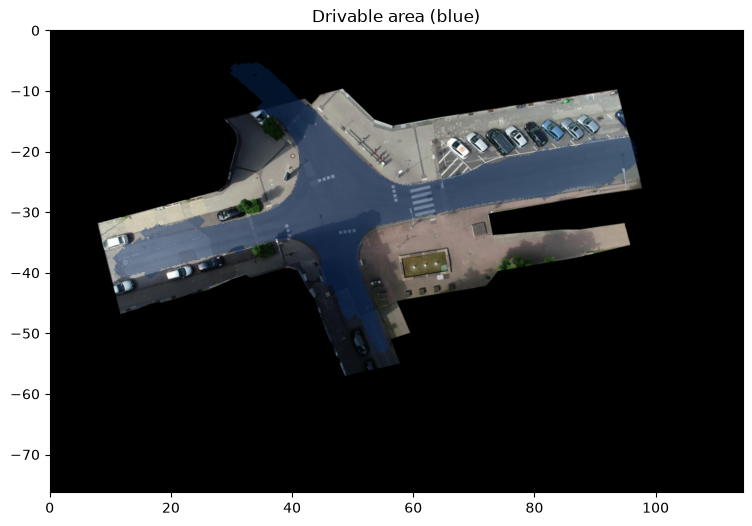

In [3]:
road = ndimage.binary_fill_holes(road)               # fill small gaps inside
road = ndimage.binary_dilation(road, iterations=4)   # grow the road by 4 cells (0.8 m)

plt.figure(figsize=(9, 6))
plt.imshow(image, extent=extent)
road_layer = np.where(road, 1.0, np.nan)              # nan = not drawn, so only the road gets colour
plt.imshow(road_layer, extent=[x0, x0 + n_cols * CELL, y0, y0 + n_rows * CELL],
           origin="lower", alpha=0.4, cmap="Blues", vmin=0, vmax=1)
plt.xlim(extent[0], extent[1]); plt.ylim(extent[2], extent[3])
plt.title("Drivable area (blue)")
plt.savefig("../figures/03_drivable_area.png", dpi=150, bbox_inches="tight")
plt.show()

## Distance map
The road rule becomes one lookup: **D(p) ≤ 0 means on the road**.

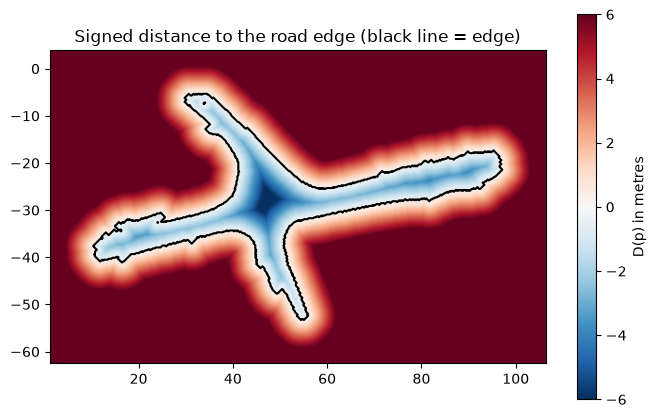

In [4]:
outside = ndimage.distance_transform_edt(~road) * CELL   # for cells outside: metres to the nearest road cell
inside = ndimage.distance_transform_edt(road) * CELL     # for cells inside: metres to the nearest non-road cell
distance = np.where(road, -inside, outside)              # negative inside the road, positive outside

plt.figure(figsize=(8, 5))
plt.imshow(np.clip(distance, -6, 6), extent=[x0, x0 + n_cols * CELL, y0, y0 + n_rows * CELL],
           origin="lower", cmap="RdBu_r")
plt.colorbar(label="D(p) in metres")
plt.contour(distance, levels=[0], extent=[x0, x0 + n_cols * CELL, y0, y0 + n_rows * CELL],
            origin="lower", colors="black")
plt.title("Signed distance to the road edge (black line = edge)")
plt.savefig("../figures/03_distance_map.png", dpi=150, bbox_inches="tight")
plt.show()

## The three rules as code
Each rule is a value g; **g ≤ 0 means the rule holds**.

| Rule | Formula |
|---|---|
| road | D(p_k) ≤ 0 |
| speed | ‖p_k − p_(k−1)‖ / Δt − 15 ≤ 0 |
| acceleration | ‖p_(k+1) − 2p_k + p_(k−1)‖ / Δt² − 6 ≤ 0 |

The acceleration rule uses the full acceleration vector, so it also rules out sharp turns at speed; no separate yaw-rate rule is needed.

In [5]:
def road_distance(points):
    # D(p) for an array of points (..., 2): look up the cell the point falls in
    cols = np.clip(((points[..., 0] - x0) / CELL).astype(int), 0, n_cols - 1)
    rows = np.clip(((points[..., 1] - y0) / CELL).astype(int), 0, n_rows - 1)
    return distance[rows, cols]

def rule_values(fut_map, p0):
    # fut_map: (N, 30, 2) future points in the map, p0: (N, 2) last history point
    # returns the three rules as "g" values: g <= 0 means the rule holds
    p = np.concatenate([p0[:, None, :], fut_map], axis=1)            # (N, 31, 2): p0, p1, ..., p30
    g_road = road_distance(fut_map)                                    # (N, 30)
    speed = np.linalg.norm(p[:, 1:] - p[:, :-1], axis=-1) / DT        # (N, 30)
    acc = np.linalg.norm(p[:, 2:] - 2 * p[:, 1:-1] + p[:, :-2], axis=-1) / DT**2   # (N, 29)
    return g_road, speed - V_MAX, acc - A_MAX

## Where do the limits come from?
The limits must let real driving pass.

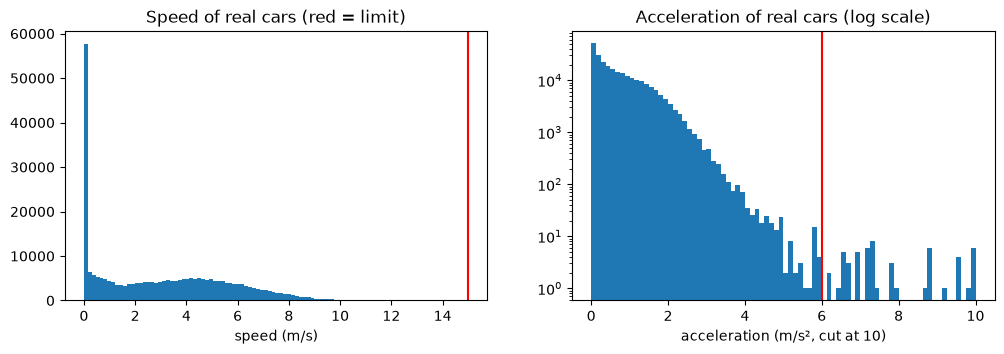

fastest real car: 12.2 m/s
99.9% of accelerations are below: 4.1 m/s²


In [6]:
p0 = train["hist_map"][:, -1]
g_road, g_speed, g_acc = rule_values(train["fut_map"], p0)
speed = g_speed + V_MAX
acc = g_acc + A_MAX

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(speed.ravel(), bins=80)
axes[0].axvline(V_MAX, color="red")
axes[0].set_xlabel("speed (m/s)")
axes[0].set_title("Speed of real cars (red = limit)")
axes[1].hist(np.clip(acc.ravel(), 0, 10), bins=80)
axes[1].axvline(A_MAX, color="red")
axes[1].set_yscale("log")
axes[1].set_xlabel("acceleration (m/s², cut at 10)")
axes[1].set_title("Acceleration of real cars (log scale)")
plt.savefig("../figures/03_limits.png", dpi=150, bbox_inches="tight")
plt.show()

print("fastest real car:", round(speed.max(), 1), "m/s")
print("99.9% of accelerations are below:", round(np.percentile(acc, 99.9), 1), "m/s²")

## Check: does real test driving pass?
This is the **reference** for the results: a strategy that keeps about 99% of its paths feasible is as feasible as real data.

In [7]:
p0 = test["hist_map"][:, -1]
g_road, g_speed, g_acc = rule_values(test["fut_map"], p0)

ok_road = (g_road <= 0).all(axis=1)       # True if all 30 points are on the road
ok_speed = (g_speed <= 0).all(axis=1)
ok_acc = (g_acc <= 0).all(axis=1)
ok_all = ok_road & ok_speed & ok_acc

print(f"road:         {ok_road.mean():.1%}")
print(f"speed:        {ok_speed.mean():.1%}")
print(f"acceleration: {ok_acc.mean():.1%}")
print(f"all three:    {ok_all.mean():.1%}")

road:         100.0%
speed:        100.0%
acceleration: 99.0%
all three:    99.0%


## Picture: a feasible and a broken path

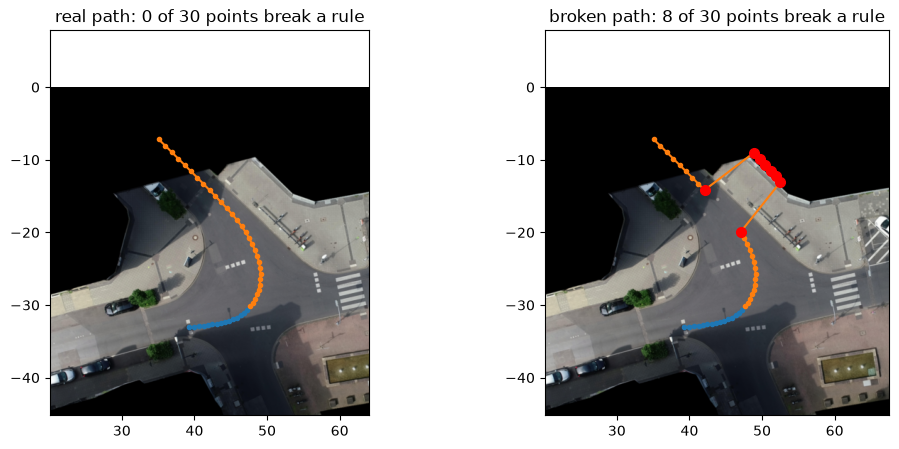

In [8]:
i = 165                                  # one test example (try others)
real = test["fut_map"][i]
broken = real.copy()
broken[15:21] += [6.0, 6.0]              # push 6 points 6 m to the side

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, path, title in [(axes[0], real, "real path"), (axes[1], broken, "broken path")]:
    g_road, g_speed, g_acc = rule_values(path[None], test["hist_map"][i:i + 1, -1])
    bad = (g_road[0] > 0) | (g_speed[0] > 0)
    bad[:-1] = bad[:-1] | (g_acc[0] > 0)   # acceleration is measured at points 1-29
    ax.imshow(image, extent=extent)
    ax.plot(test["hist_map"][i, :, 0], test["hist_map"][i, :, 1], "o-", color="tab:blue", markersize=3)
    ax.plot(path[:, 0], path[:, 1], "o-", color="tab:orange", markersize=3)
    ax.plot(path[bad, 0], path[bad, 1], "o", color="red", markersize=7)
    ax.set_xlim(path[:, 0].min() - 15, path[:, 0].max() + 15)
    ax.set_ylim(path[:, 1].min() - 15, path[:, 1].max() + 15)
    ax.set_title(f"{title}: {bad.sum()} of 30 points break a rule")
plt.savefig("../figures/03_feasible_vs_broken.png", dpi=150, bbox_inches="tight")
plt.show()

## Save the road grid

In [9]:
np.savez(f"{OUT}road_grid.npz", road=road, distance=distance.astype(np.float32),
         x0=x0, y0=y0, cell=CELL)
print("saved")

saved
